# 01 · The Newsvendor

**The single most common inventory mistake is stocking to the forecast.**

Demand for a season is uncertain. Every unsold unit is written off at the *overage*
cost; every unit you run short of is a lost sale at the *underage* cost. Intuition
says order expected demand. The newsvendor model says order the **critical-ratio
quantile** of the demand distribution:

$$ Q^* = F^{-1}\!\left(\frac{c_u}{c_u + c_o}\right) $$

When a stockout costs more than a leftover, that quantile sits *above* the mean, and
stocking to the mean leaves a computable amount of money on the table every season.

Figures are saved to `outputs/figures/`, inputs and results to `outputs/data/`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from src.config import SETTINGS
from src.evaluation.sensitivity import (
    newsvendor_cost_ratio_sweep,
    newsvendor_uncertainty_sweep,
)
from src.inventory.newsvendor import solve_newsvendor
from src.outputs import save_figure, save_json

plt.rcParams["figure.figsize"] = (7, 4)
nv = SETTINGS.newsvendor
nv

NewsvendorConfig(underage_cost=3.0, overage_cost=1.0, demand_mean=100.0, demand_std=25.0)

## The decision and its inputs

We read the cost structure and demand distribution from `config/settings.yaml`. A
stockout costs three times a leftover here, so the critical ratio is 0.75 — we should
stock the **75th percentile** of demand.

In [2]:
inputs = {
    "underage_cost": nv.underage_cost,
    "overage_cost": nv.overage_cost,
    "demand_mean": nv.demand_mean,
    "demand_std": nv.demand_std,
}
save_json(inputs, "01_inputs")

solution = solve_newsvendor(nv.underage_cost, nv.overage_cost, nv.demand_mean, nv.demand_std)
save_json(solution, "01_newsvendor_solution")

print(f"critical ratio        : {solution.critical_ratio:.3f}")
print(f"optimal quantity      : {solution.optimal_quantity:.1f}")
print(f"stock-to-mean quantity: {solution.mean_quantity:.1f}")
print(f"optimal expected cost : {solution.optimal_cost:.2f}")
print(f"stock-to-mean cost    : {solution.mean_cost:.2f}")
print(f"cost left on the table: {solution.cost_gap:.2f}")

critical ratio        : 0.750
optimal quantity      : 116.9
stock-to-mean quantity: 100.0
optimal expected cost : 31.78
stock-to-mean cost    : 39.89
cost left on the table: 8.12


## The optimum is a quantile, not the mean

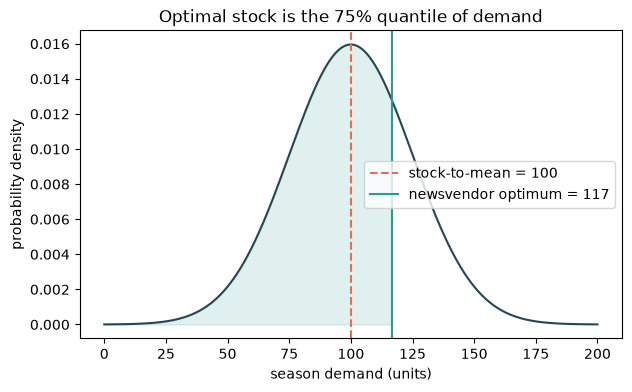

In [3]:
grid = np.linspace(nv.demand_mean - 4 * nv.demand_std, nv.demand_mean + 4 * nv.demand_std, 400)
pdf = stats.norm.pdf(grid, nv.demand_mean, nv.demand_std)

fig, ax = plt.subplots()
ax.plot(grid, pdf, color="#264653")
ax.fill_between(grid, pdf, where=grid <= solution.optimal_quantity, color="#2a9d8f", alpha=0.15)
ax.axvline(solution.mean_quantity, color="#e76f51", linestyle="--",
           label=f"stock-to-mean = {solution.mean_quantity:.0f}")
ax.axvline(solution.optimal_quantity, color="#2a9d8f",
           label=f"newsvendor optimum = {solution.optimal_quantity:.0f}")
ax.set_xlabel("season demand (units)")
ax.set_ylabel("probability density")
ax.set_title(f"Optimal stock is the {solution.critical_ratio:.0%} quantile of demand")
ax.legend()
save_figure(fig, "01_optimal_vs_mean")
plt.show()

## The gap grows with cost asymmetry

Sweep the stockout/leftover cost ratio from symmetric (1×) upward. At 1× the optimum
*is* the mean and the gap is zero; as stockouts get more expensive relative to
leftovers, stocking to the mean costs more and more.

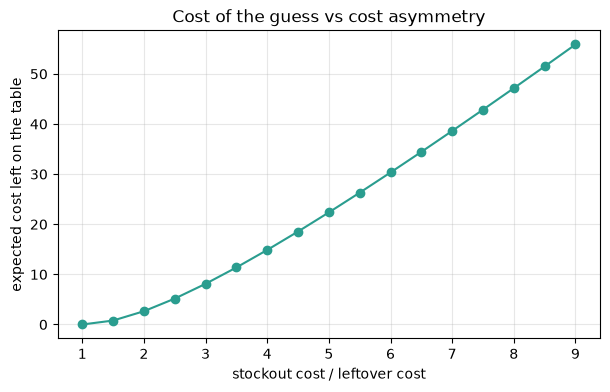

In [4]:
ratios = np.linspace(1.0, 9.0, 17)
ratio_x, ratio_gaps = newsvendor_cost_ratio_sweep(ratios, nv.overage_cost, nv.demand_mean, nv.demand_std)
save_json({"cost_ratio": ratio_x, "cost_gap": ratio_gaps}, "01_gap_vs_cost_ratio")

fig, ax = plt.subplots()
ax.plot(ratio_x, ratio_gaps, marker="o", color="#2a9d8f")
ax.set_xlabel("stockout cost / leftover cost")
ax.set_ylabel("expected cost left on the table")
ax.set_title("Cost of the guess vs cost asymmetry")
ax.grid(alpha=0.3)
save_figure(fig, "01_gap_vs_cost_ratio")
plt.show()

## The gap grows with demand uncertainty

Hold the costs fixed and widen the demand distribution. More uncertainty means the
mean is a worse stand-in for the right quantile, so the money left on the table grows.

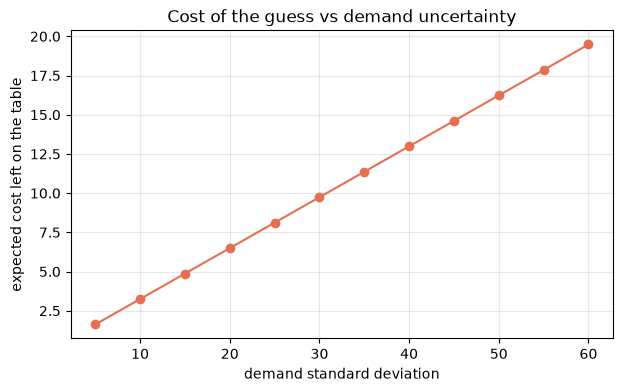

In [5]:
stds = np.linspace(5.0, 60.0, 12)
std_x, std_gaps = newsvendor_uncertainty_sweep(stds, nv.underage_cost, nv.overage_cost, nv.demand_mean)
save_json({"demand_std": std_x, "cost_gap": std_gaps}, "01_gap_vs_uncertainty")

fig, ax = plt.subplots()
ax.plot(std_x, std_gaps, marker="o", color="#e76f51")
ax.set_xlabel("demand standard deviation")
ax.set_ylabel("expected cost left on the table")
ax.set_title("Cost of the guess vs demand uncertainty")
ax.grid(alpha=0.3)
save_figure(fig, "01_gap_vs_uncertainty")
plt.show()

## Takeaway

The optimal order quantity is a **quantile of the demand distribution**, chosen by the
ratio of stockout to leftover cost — not the forecast. Stocking to the mean is
systematically wrong whenever those two costs differ, and the error grows with both the
cost asymmetry and the demand uncertainty. This is the same asymmetric-cost logic as
choosing a classification threshold, applied to inventory.

In [6]:
takeaways = {
    "thesis": "Optimal single-period stock is the critical-ratio quantile of demand, not the mean.",
    "critical_ratio": round(solution.critical_ratio, 4),
    "units_above_mean": round(solution.optimal_quantity - solution.mean_quantity, 2),
    "cost_left_by_stocking_to_mean": round(solution.cost_gap, 2),
}
save_json(takeaways, "01_takeaways")
takeaways

{'thesis': 'Optimal single-period stock is the critical-ratio quantile of demand, not the mean.',
 'critical_ratio': 0.75,
 'units_above_mean': 16.86,
 'cost_left_by_stocking_to_mean': 8.12}